# Immune landscape of ER+ breast cancer: IDC vs ILC

Single-cell RNA-seq, from the GEO archives through to the comparison.

**Question**

- ER+ disease is ~70% of breast cancer and responds poorly to checkpoint immunotherapy.
- Invasive ductal (IDC) and invasive lobular (ILC) carcinoma are treated similarly.
- Do they have the same immune composition? Paired blood and tumour from the same patients.

**Data**

- [GSE193911](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE193911) — Onkar, Cui, Zou *et al.*, *Nature Cancer* **4**, 516–534 (2023), [doi:10.1038/s43018-023-00527-w](https://doi.org/10.1038/s43018-023-00527-w)
- Live CD45+ cells, 10x 3' v3. Most patients were hashed so PBMC and TIL share a lane.
- I was the computational author on that paper. This is a re-analysis of the public data, not a reproduction of its figures.

**Samples**

| | ILC | IDC |
|---|---|---|
| hashed (PBMC + TIL on one lane) | BC1, BC4, BC5 | BC2\*, BC3, BC6, BC8 |
| separate libraries | BC11, BC12, BC15 | BC13, BC14 |

- \* BC2's hashing failed. It is downloaded deliberately — §2 covers how that shows up and why it goes.
- Tumour arm ends up at 5 IDC vs 6 ILC. The blood arm is smaller.

Six points in the notebook are marked **Decision**. They are the places where a different choice changes the result.

---

## 0. Setup

Run `bash 00_download_data.sh` first. It pulls ~35 MB from GEO and writes `data/sample_manifest.csv`.

In [1]:
import os, gzip, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse, stats

# library deprecation chatter would otherwise bury the output (and print the
# full interpreter path on every line)
for cat in (FutureWarning, DeprecationWarning, UserWarning, RuntimeWarning):
    warnings.simplefilter("ignore", category=cat)
sc.settings.verbosity = 1

SEED = 0
np.random.seed(SEED)

DATA = Path("data")
FIGS = Path("figures"); FIGS.mkdir(exist_ok=True)

sc.settings.set_figure_params(dpi=90, dpi_save=200, frameon=False, figsize=(4.5, 4.5))
sns.set_style("ticks")

print(f"scanpy {sc.__version__} | anndata {ad.__version__} | pandas {pd.__version__}")
# --- small plotting helpers, matplotlib only -------------------------------
# seaborn's violin/strip path is version-fragile; these keep the notebook
# portable across environments.

def strip_by_group(ax, df, xcol, ycol, order=None, colour="#2e7d8f", jitter=0.08, s=22):
    # One dot per row, jittered within its category.
    order = order if order is not None else sorted(df[xcol].dropna().unique())
    rng = np.random.default_rng(SEED)
    for i, g in enumerate(order):
        v = df.loc[df[xcol] == g, ycol].values
        ax.scatter(i + rng.uniform(-jitter, jitter, len(v)), v,
                   s=s, color=colour, alpha=.85, edgecolor="white", linewidth=.5, zorder=3)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
    return order


def violin_by_group(ax, df, xcol, ycol, order=None, colours=None, log=False):
    # Matplotlib violin + median bar; no seaborn, no KDE surprises.
    order = order if order is not None else sorted(df[xcol].dropna().unique())
    data = [df.loc[df[xcol] == g, ycol].dropna().values for g in order]
    data = [d if len(d) > 1 else np.array([0.0, 0.0]) for d in data]
    parts = ax.violinplot(data, positions=range(len(order)), showextrema=False, widths=.8)
    colours = colours or ["#2e7d8f"] * len(order)
    for body, c in zip(parts["bodies"], colours):
        body.set_facecolor(c); body.set_alpha(.55); body.set_edgecolor("none")
    for i, d in enumerate(data):
        ax.hlines(np.median(d), i - .28, i + .28, color="0.15", lw=1.4, zorder=4)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
    if log: ax.set_yscale("log")
    return order

scanpy 1.11.5 | anndata 0.11.4 | pandas 2.3.3


In [2]:
manifest = pd.read_csv(DATA / "sample_manifest.csv")
manifest

,patient,subtype,assay,gsm,dir,compartment
0,BC1,ILC,GEX,GSM5823462,BC1_PBMC_TIL_GEX,hashed
1,BC1,ILC,HTO,GSM5823479,BC1_PBMC_TIL_CITEseq,hashed
2,BC4,ILC,GEX,GSM5823465,BC4_PBMC_TIL_GEX,hashed
3,BC4,ILC,HTO,GSM5823482,BC4_PBMC_TIL_CITESEQ,hashed
4,BC5,ILC,GEX,GSM5823466,BC5_PBMC_TIL_GEX,hashed
5,BC5,ILC,HTO,GSM5823483,BC5_PBMC_TIL_CITESEQ,hashed
6,BC2,IDC,GEX,GSM5823463,BC2_PBMC_TIL_GEX,hashed
7,BC2,IDC,HTO,GSM5823480,BC2_PBMC_TIL_CITEseq,hashed
8,BC3,IDC,GEX,GSM5823464,BC3_PBMC_TIL_GEX,hashed
9,BC3,IDC,HTO,GSM5823481,BC3_PBMC_TIL_CITEseq,hashed


## 1. Loading expression and hashtag matrices

- Two matrices per hashed patient: gene expression (GEX) and TotalSeq hashtag counts (HTO).
- They are separate GEO samples, so they need to be matched on cell barcode.

In [3]:
def read_10x_dir(path: Path) -> ad.AnnData:
    # Read a barcodes/features/matrix triplet into AnnData (cells x features).
    a = sc.read_mtx(path / "matrix.mtx.gz").T                       # mtx is features x cells
    feats = pd.read_csv(path / "features.tsv.gz", sep="\t", header=None)
    bcs   = pd.read_csv(path / "barcodes.tsv.gz",  sep="\t", header=None)
    # index on the Ensembl ID, not the symbol: this series mixes two
    # CellRanger reference builds and symbols are not stable between them
    a.var_names = feats[0].astype(str)
    a.var["symbol"] = (feats[1].astype(str) if feats.shape[1] > 1 else feats[0].astype(str)).values
    a.obs_names = bcs[0].astype(str)
    a.var_names_make_unique()
    return a


def by_symbol(a, genes):
    # Ensembl IDs present in `a` for the requested gene symbols.
    lut = pd.Series(a.var_names.values, index=a.var["symbol"].values)
    lut = lut[~lut.index.duplicated()]
    return [lut[g] for g in genes if g in lut.index]


# two kinds of sample in this series:
#   compartment == "hashed"  -> PBMC and TIL share a lane, needs demultiplexing
#   compartment in PBMC/TIL  -> separate library, compartment already known
hashed = manifest.query("compartment == 'hashed'")
separate = manifest.query("compartment != 'hashed'")

gex_dirs = hashed.query("assay == 'GEX'").set_index("patient")["dir"].to_dict()
hto_dirs = hashed.query("assay == 'HTO'").set_index("patient")["dir"].to_dict()
subtype  = manifest.drop_duplicates("patient").set_index("patient")["subtype"].to_dict()
patients = list(gex_dirs)

print(f"hashed patients   : {patients}")
print(f"separate libraries: {sorted(separate['patient'].unique())}")

gex = {p: read_10x_dir(DATA / gex_dirs[p]) for p in patients}
hto = {p: read_10x_dir(DATA / hto_dirs[p]) for p in patients}

pd.DataFrame(
    {"subtype": subtype,
     "GEX cells": {p: gex[p].n_obs for p in patients},
     "GEX genes": {p: gex[p].n_vars for p in patients},
     "HTO cells": {p: hto[p].n_obs for p in patients},
     "HTO tags":  {p: hto[p].n_vars for p in patients}}
).loc[patients]

hashed patients   : ['BC1', 'BC4', 'BC5', 'BC2', 'BC3', 'BC6', 'BC8']
separate libraries: ['BC11', 'BC12', 'BC13', 'BC14', 'BC15']


,subtype,GEX cells,GEX genes,HTO cells,HTO tags
BC1,ILC,3344.0,33538.0,3225.0,21.0
BC4,ILC,3014.0,33538.0,2888.0,13.0
BC5,ILC,3123.0,33538.0,3074.0,13.0
BC2,IDC,657.0,33538.0,657.0,13.0
BC3,IDC,2243.0,33538.0,2235.0,13.0
BC6,IDC,1839.0,33538.0,1572.0,199.0
BC8,IDC,2645.0,33538.0,2599.0,13.0


The barcodes do not match directly:

In [4]:
p = "BC1"
print("GEX barcodes:", list(gex[p].obs_names[:2]))
print("HTO barcodes:", list(hto[p].obs_names[:2]))
print("naive intersection:", len(set(gex[p].obs_names) & set(hto[p].obs_names)))

GEX barcodes: ['AAACCTGAGCCCAACC-1', 'AAACCTGAGTAGCCGA-1']
HTO barcodes: ['ACACCAAAGTGTACTC', 'GACGTGCAGTCCCACG']
naive intersection: 0


- CellRanger adds a `-1` lane suffix. The hashtag counts came from another tool and have the bare 16-mer.
- Stripping the suffix matches them.
- Also checked whether the HTO whitelist was reverse-complemented. It is not.

In [5]:
for p in patients:
    gex[p].obs["bc16"] = [b.split("-")[0] for b in gex[p].obs_names]
    hto[p].obs["bc16"] = [b.split("-")[0] for b in hto[p].obs_names]

rc = str.maketrans("ACGT", "TGCA")
rows = []
for p in patients:
    g, h = set(gex[p].obs["bc16"]), set(hto[p].obs["bc16"])
    h_rc = {b.translate(rc)[::-1] for b in h}
    rows.append({"patient": p, "GEX": len(g), "HTO": len(h),
                 "matched": len(g & h), "if revcomp": len(g & h_rc),
                 "% GEX with HTO": round(100 * len(g & h) / len(g), 1)})
pd.DataFrame(rows).set_index("patient")

,GEX,HTO,matched,if revcomp,% GEX with HTO
patient,,,,,
BC1,3344,3225,3225,0,96.4
BC4,3014,2888,2888,0,95.8
BC5,3123,3074,3074,0,98.4
BC2,657,657,657,0,100.0
BC3,2243,2235,2235,0,99.6
BC6,1839,1572,1572,0,85.5
BC8,2645,2599,2599,0,98.3


## 2. Getting the compartment label

Blood vs tumour is not in the expression matrix. It is only in the hashtag counts, so the hashing has to be checked per patient first.

- The tag pair differs between patients, so it cannot be hardcoded.
- An `unmapped` row collects reads matching no tag. Its size relative to the real tags says how well the staining worked.

In [6]:
hto_stats = []
for p in patients:
    counts = np.asarray(hto[p].X.sum(axis=0)).ravel()
    s = pd.Series(counts, index=hto[p].var_names).sort_values(ascending=False)
    real = s.drop("unmapped", errors="ignore")
    top2 = real.index[:2].tolist()
    hto_stats.append({
        "patient": p, "subtype": subtype[p],
        "tag_1": top2[0].split("-")[0], "n_1": int(real.iloc[0]),
        "tag_2": top2[1].split("-")[0], "n_2": int(real.iloc[1]),
        "unmapped": int(s.get("unmapped", 0)),
        "top2 / unmapped": round(real.iloc[:2].sum() / max(s.get("unmapped", 1), 1), 1),
        "tag balance": round(real.iloc[1] / real.iloc[0], 3),
    })
hto_stats = pd.DataFrame(hto_stats).set_index("patient")
hto_stats

,subtype,tag_1,n_1,tag_2,n_2,unmapped,top2 / unmapped,tag balance
patient,,,,,,,,
BC1,ILC,h_totalseq_2,1814258,h_totalseq_1,1557250,454101,7.4,0.858
BC4,ILC,totalseq_1,3163777,totalseq_2,2869285,779268,7.7,0.907
BC5,ILC,totalseq_1,3821613,totalseq_2,2452645,624594,10.0,0.642
BC2,IDC,totalseq_2,6241,totalseq_1,377,33419,0.2,0.060
BC3,IDC,totalseq_2,1221410,totalseq_3,583097,207784,8.7,0.477
BC6,IDC,totalseq_1,2080007,totalseq_4,1562724,492177,7.4,0.751
BC8,IDC,totalseq_2,2480431,totalseq_1,719441,314429,10.2,0.290


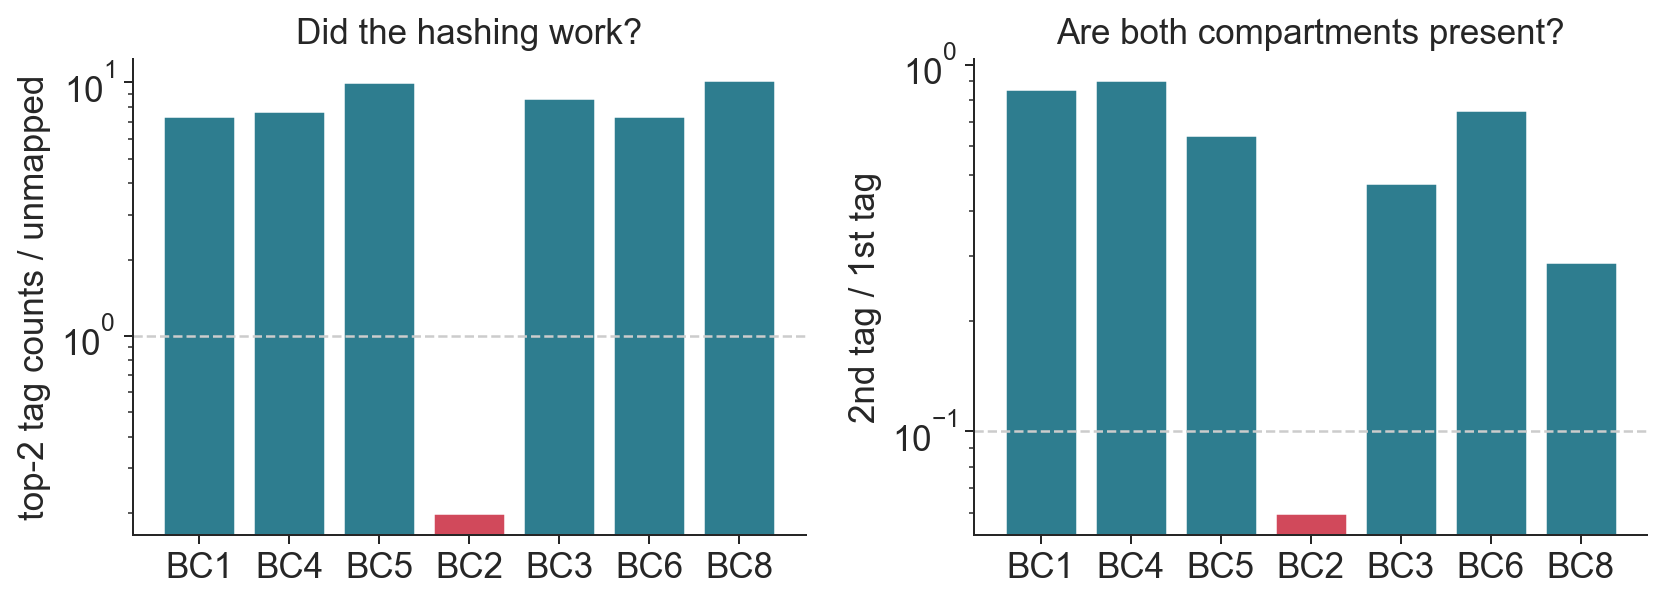

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.6))

ax = axes[0]
ax.axhline(1, color="0.8", lw=1, ls="--")
cols = ["#d1495b" if v < 1 else "#2e7d8f" for v in hto_stats["top2 / unmapped"]]
ax.bar(hto_stats.index, hto_stats["top2 / unmapped"], color=cols)
ax.set_yscale("log"); ax.set_ylabel("top-2 tag counts / unmapped")
ax.set_title("Did the hashing work?")

ax = axes[1]
ax.axhline(0.1, color="0.8", lw=1, ls="--")
cols = ["#d1495b" if v < 0.1 else "#2e7d8f" for v in hto_stats["tag balance"]]
ax.bar(hto_stats.index, hto_stats["tag balance"], color=cols)
ax.set_yscale("log"); ax.set_ylabel("2nd tag / 1st tag")
ax.set_title("Are both compartments present?")

for a in axes: sns.despine(ax=a)
fig.tight_layout(); fig.savefig(FIGS / "01_hashing_qc.png", bbox_inches="tight"); plt.show()

> ### Decision 1 — drop BC2
>
> - BC2's two real tags together carry fewer reads than `unmapped`.
> - Its second tag is at ~6% of the first, so one compartment is basically missing.
> - Any demultiplexing call for BC2 would be noise, and compartment is one of the two factors here.
> - Keeping it would spread 657 cells of unknown origin across both compartments of one subtype and shift every proportion downstream.
>
> Dropped. The remaining hashed set is 3 ILC and 3 IDC.

In [8]:
FAILED = ["BC2"]
patients = [p for p in patients if p not in FAILED]
print("analysed:", patients)
print("          ", {p: subtype[p] for p in patients})

analysed: ['BC1', 'BC4', 'BC5', 'BC3', 'BC6', 'BC8']
           {'BC1': 'ILC', 'BC4': 'ILC', 'BC5': 'ILC', 'BC3': 'IDC', 'BC6': 'IDC', 'BC8': 'IDC'}


### 2b. Calling cells

- CLR-normalise each tag, then: one tag above threshold = singlet, both = doublet, neither = negative.
- Thresholds are per tag, taken from that tag's own distribution.
- Staining efficiency varies between patients, so a single global cutoff would not transfer.

In [9]:
def clr(x: np.ndarray) -> np.ndarray:
    # Centred log-ratio across cells, per tag.
    lx = np.log1p(x)
    return lx - lx.mean()


demux = {}
for p in patients:
    tags = [hto_stats.loc[p, "tag_1"], hto_stats.loc[p, "tag_2"]]
    full = [v for v in hto[p].var_names if v.split("-")[0] in tags]
    m = hto[p][:, full].X
    m = np.asarray(m.todense() if sparse.issparse(m) else m, dtype=float)

    z = np.column_stack([clr(m[:, i]) for i in range(m.shape[1])])
    # Otsu-style split of each tag's own CLR distribution
    thr = [np.percentile(z[:, i], 55) for i in range(z.shape[1])]
    pos = z > np.array(thr)

    call = np.where(pos.sum(1) == 1,
                    np.where(pos[:, 0], "tag_1", "tag_2"),
                    np.where(pos.sum(1) == 2, "doublet", "negative"))
    demux[p] = pd.DataFrame({"bc16": hto[p].obs["bc16"].values, "hash_call": call,
                             "z1": z[:, 0], "z2": z[:, 1]})

summary = pd.DataFrame({p: demux[p]["hash_call"].value_counts() for p in patients}).T.fillna(0).astype(int)
summary["% singlet"] = (100 * (summary.get("tag_1", 0) + summary.get("tag_2", 0)) / summary.sum(axis=1)).round(1)
summary

hash_call,doublet,negative,tag_1,tag_2,% singlet
BC1,792,1123,659,651,40.6
BC4,295,596,1003,994,69.1
BC5,416,775,965,918,61.3
BC3,87,310,919,919,82.2
BC6,82,240,625,625,79.5
BC8,452,729,700,718,54.6


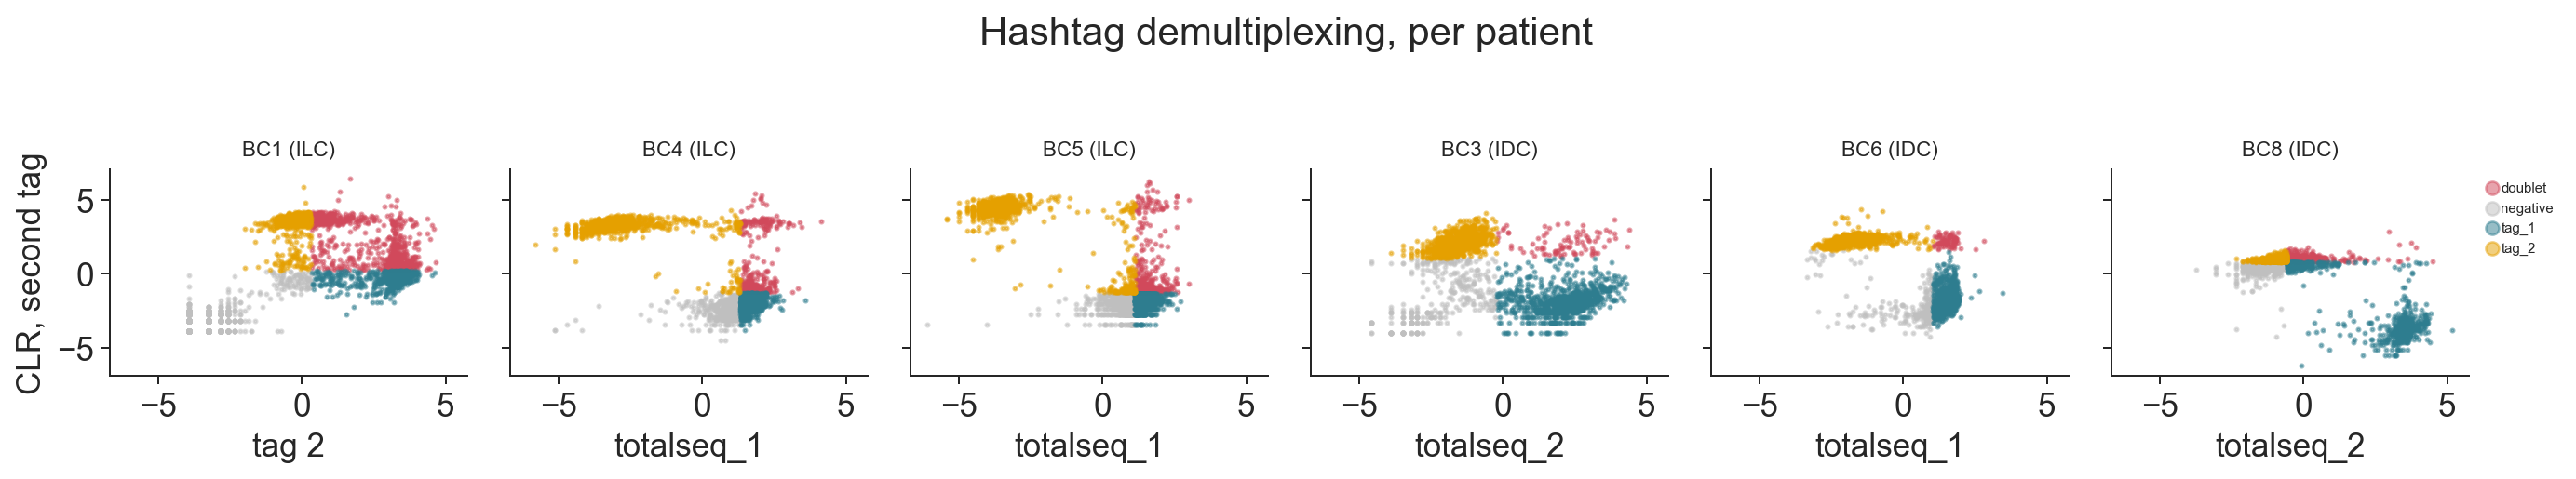

In [10]:
fig, axes = plt.subplots(1, len(patients), figsize=(2.6 * len(patients), 2.8), sharex=True, sharey=True)
pal = {"tag_1": "#2e7d8f", "tag_2": "#e5a000", "doublet": "#d1495b", "negative": "0.75"}
for ax, p in zip(np.atleast_1d(axes), patients):
    d = demux[p]
    for k, g in d.groupby("hash_call"):
        ax.scatter(g["z1"], g["z2"], s=2, alpha=.5, c=pal.get(k, "k"), label=k, rasterized=True)
    ax.set_title(f"{p} ({subtype[p]})", fontsize=9)
    ax.set_xlabel(hto_stats.loc[p, "tag_1"].replace("h_totalseq_", "tag "))
    sns.despine(ax=ax)
np.atleast_1d(axes)[0].set_ylabel("CLR, second tag")
np.atleast_1d(axes)[-1].legend(markerscale=4, fontsize=6, frameon=False,
                               loc="upper left", bbox_to_anchor=(1.02, 1))
fig.suptitle("Hashtag demultiplexing, per patient", y=1.04)
fig.tight_layout(); fig.savefig(FIGS / "02_demux.png", bbox_inches="tight"); plt.show()

## 3. Which tag is blood, which is tumour

Tag numbers are arbitrary and differ between patients. The hashtag data cannot say which is which, so the assignment comes from expression.

- Blood-skewed: `SELL`, `CCR7`, `S1PR1`, `KLF2`, `TCF7`
- Tissue-skewed: `CXCL13`, `ITGAE`, `RGS1`, `HSPA1A`, `NR4A1`, `CD69`
- Mitochondrial fraction, which runs higher in dissociated tumour

These work regardless of which cell types dominate the sample.

In [11]:
BLOOD = ["SELL", "CCR7", "S1PR1", "KLF2", "TCF7"]
TISSUE = ["CXCL13", "ITGAE", "RGS1", "HSPA1A", "NR4A1", "CD69"]

def compartment_score(a: ad.AnnData, genes):
    present = by_symbol(a, genes)
    if not present: return np.zeros(a.n_obs)
    x = a[:, present].X
    x = np.asarray(x.todense() if sparse.issparse(x) else x, dtype=float)
    x = np.log1p(x / np.maximum(np.asarray(a.X.sum(1)).ravel()[:, None], 1) * 1e4)
    return x.mean(1)


assign = {}
for p in patients:
    a = gex[p]
    d = demux[p].set_index("bc16")
    keep = [b for b in a.obs["bc16"] if b in d.index]
    sub = a[a.obs["bc16"].isin(keep)].copy()
    sub.obs["hash_call"] = d.loc[sub.obs["bc16"], "hash_call"].values

    mito = sub.var_names[sub.var["symbol"].str.startswith("MT-")].tolist()
    sub.obs["pct_mito"] = 100 * np.asarray(sub[:, mito].X.sum(1)).ravel() / np.maximum(np.asarray(sub.X.sum(1)).ravel(), 1)
    sub.obs["blood_score"]  = compartment_score(sub, BLOOD)
    sub.obs["tissue_score"] = compartment_score(sub, TISSUE)

    stat = sub.obs[sub.obs["hash_call"].isin(["tag_1", "tag_2"])].groupby("hash_call")[
        ["blood_score", "tissue_score", "pct_mito"]].mean()
    delta = (stat["blood_score"] - stat["tissue_score"])
    blood_tag = delta.idxmax()
    sub.obs["compartment"] = sub.obs["hash_call"].map(
        lambda c: "PBMC" if c == blood_tag else ("TIL" if c in ("tag_1", "tag_2") else c))
    sub.obs["patient"], sub.obs["subtype"] = p, subtype[p]
    assign[p] = sub
    print(f"{p}: {blood_tag} -> PBMC   (blood-tissue score gap "
          f"{delta[blood_tag]:.2f} vs {delta.drop(blood_tag).iloc[0]:.2f}, "
          f"mito {stat.loc[blood_tag, 'pct_mito']:.1f}% vs "
          f"{stat.drop(blood_tag)['pct_mito'].iloc[0]:.1f}%)")

BC1: tag_2 -> PBMC   (blood-tissue score gap 0.06 vs -0.07, mito 2.4% vs 2.4%)
BC4: tag_2 -> PBMC   (blood-tissue score gap 0.24 vs -0.15, mito 6.9% vs 9.3%)
BC5: tag_2 -> PBMC   (blood-tissue score gap 0.30 vs -0.05, mito 6.2% vs 6.8%)
BC3: tag_2 -> PBMC   (blood-tissue score gap 0.13 vs -0.59, mito 4.4% vs 4.6%)


BC6: tag_2 -> PBMC   (blood-tissue score gap -0.07 vs -0.71, mito 6.4% vs 10.3%)
BC8: tag_2 -> PBMC   (blood-tissue score gap 0.20 vs 0.03, mito 5.4% vs 6.3%)


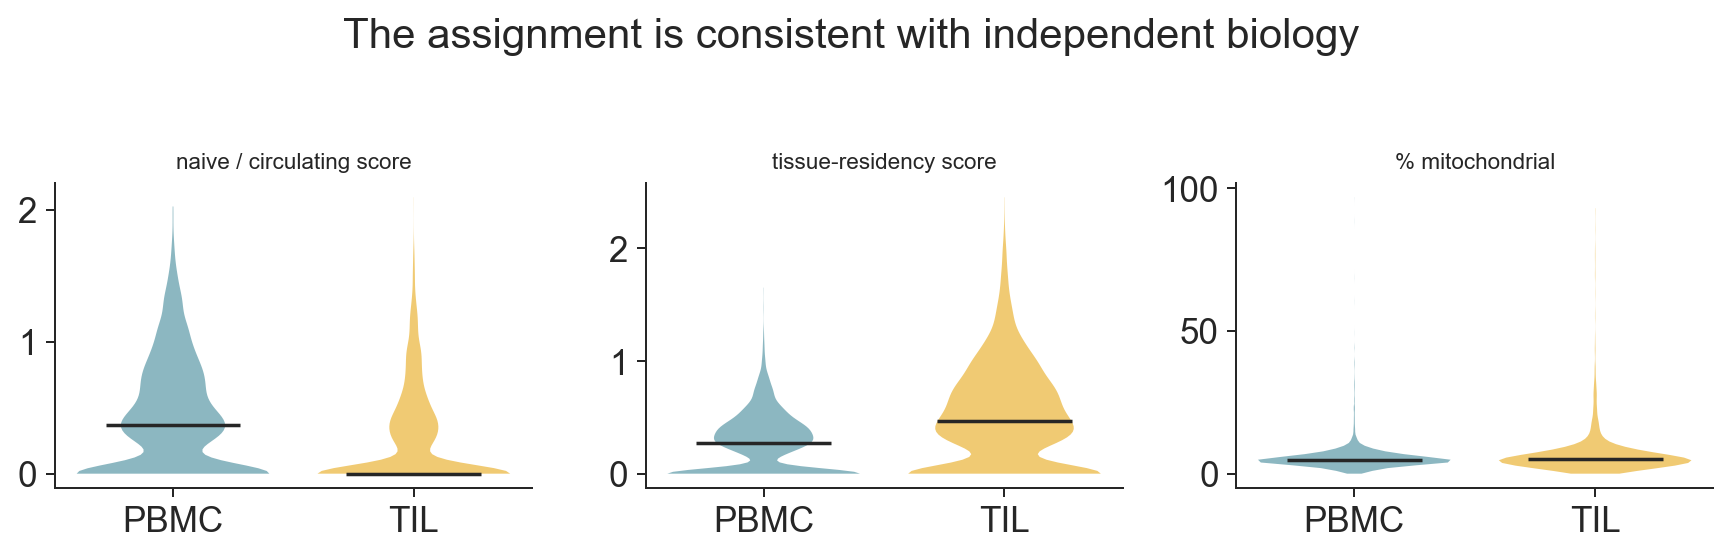

compartment,PBMC,TIL
patient,,
BC1,651,659
BC3,919,919
BC4,994,1003
BC5,918,965
BC6,625,625
BC8,718,700


In [12]:
# barcodes repeat across patients, so drop the index before concatenating
chk = pd.concat([a.obs[["patient", "subtype", "compartment", "blood_score", "tissue_score", "pct_mito"]]
                 for a in assign.values()]).reset_index(drop=True)
chk = chk[chk["compartment"].isin(["PBMC", "TIL"])]

fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, col, lab in zip(axes, ["blood_score", "tissue_score", "pct_mito"],
                        ["naive / circulating score", "tissue-residency score", "% mitochondrial"]):
    violin_by_group(ax, chk, "compartment", col, order=["PBMC", "TIL"],
                    colours=["#2e7d8f", "#e5a000"])
    ax.set_title(lab, fontsize=9)
    sns.despine(ax=ax)
fig.suptitle("The assignment is consistent with independent biology", y=1.04)
fig.tight_layout(); fig.savefig(FIGS / "03_compartment_check.png", bbox_inches="tight"); plt.show()

pd.crosstab(chk["patient"], chk["compartment"])

## 3b. Adding the samples that were not hashed

> ### Decision 2 — two library types in one analysis
>
> - BC11–BC15 were run as separate libraries. Their compartment is in the GEO title, so no demultiplexing is needed.
> - They roughly double the tumour arm, which is what makes the IDC/ILC comparison possible at all.
> - A hashed TIL and a separate-library TIL went through different wet-lab handling, so they are not automatically comparable. The risk is a library-type effect read as a subtype effect.
> - `sample_type` is carried as a covariate, QC is compared between the two groups before pooling, and the integration is checked for residual `sample_type` structure afterwards.

In [13]:
sep_rows = separate.query("assay == 'GEX'")
for r in sep_rows.itertuples():
    a = read_10x_dir(DATA / r.dir)
    a.obs["bc16"] = [b.split("-")[0] for b in a.obs_names]
    mito = a.var_names[a.var["symbol"].str.startswith("MT-")].tolist()
    a.obs["pct_mito"] = 100 * np.asarray(a[:, mito].X.sum(1)).ravel() / np.maximum(np.asarray(a.X.sum(1)).ravel(), 1)
    a.obs["blood_score"]  = compartment_score(a, BLOOD)
    a.obs["tissue_score"] = compartment_score(a, TISSUE)
    a.obs["hash_call"]    = "not_hashed"
    a.obs["compartment"]  = r.compartment
    a.obs["patient"], a.obs["subtype"] = r.patient, r.subtype
    assign[f"{r.patient}_{r.compartment}"] = a

for k in list(assign):
    assign[k].obs["sample_type"] = "separate" if "_" in k else "hashed"

tally = (pd.concat([a.obs[["patient", "subtype", "compartment", "sample_type"]] for a in assign.values()])
         .reset_index(drop=True)
         .drop_duplicates()
         .groupby(["compartment", "subtype"], observed=True)["patient"].nunique()
         .unstack(fill_value=0))
print("patients per arm after folding in the separate libraries:")
tally

patients per arm after folding in the separate libraries:


subtype,IDC,ILC
compartment,,
PBMC,4,4
TIL,5,6
doublet,3,3
negative,3,3


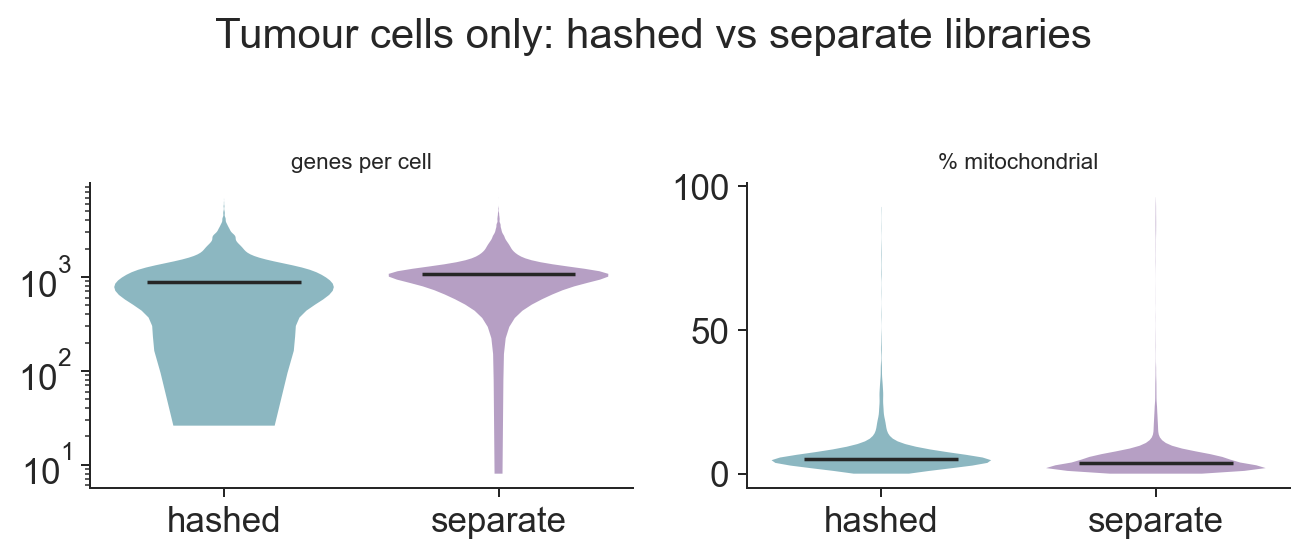

,n_genes,pct_mito
sample_type,,
hashed,891.0,5.0
separate,1081.0,3.6


In [14]:
# do the two sample types look comparable before they are pooled?
qc = pd.concat([a.obs[["patient", "compartment", "sample_type", "pct_mito"]] for a in assign.values()]).reset_index(drop=True)
qc["n_genes"] = np.concatenate([np.asarray((a.X > 0).sum(1)).ravel() for a in assign.values()])
qc = qc[qc["compartment"] == "TIL"]

fig, axes = plt.subplots(1, 2, figsize=(7.5, 3))
for ax, col, lab in zip(axes, ["n_genes", "pct_mito"], ["genes per cell", "% mitochondrial"]):
    violin_by_group(ax, qc, "sample_type", col, order=["hashed", "separate"],
                    colours=["#2e7d8f", "#7a5195"], log=(col == "n_genes"))
    ax.set_title(lab, fontsize=9)
    sns.despine(ax=ax)
fig.suptitle("Tumour cells only: hashed vs separate libraries", y=1.04)
fig.tight_layout(); fig.savefig(FIGS / "03b_sample_type.png", bbox_inches="tight"); plt.show()

qc.groupby("sample_type", observed=True)[["n_genes", "pct_mito"]].median().round(1)

## 3c. Two reference builds in one series

> ### Decision 3 — join on Ensembl IDs
>
> - Most samples have 33,538 features. BC13 and BC15 have 32,738 — a different CellRanger reference.
> - `AnnData.concat` joins on `var_names`. With symbols as the index the shared set drops to 20,453 genes.
> - That loss is annotation drift, not biology. `TRAC` and `JCHAIN` are among the genes lost, and both are used here.
> - Indexing on Ensembl IDs brings the shared set back to 30,800. Symbols are restored as the index afterwards.
> - `TRAC` really is absent from the older build, so it comes out of the marker panel instead of returning zeros.

## 4. Cell-level QC

- Thresholds are loose. These are sorted CD45+ cells: plasma cells have few genes, and dissociated TIL have more mitochondrial reads than PBMC.
- A single global mitochondrial cut would remove tumour myeloid cells preferentially, which is the population of interest.
- Mitochondrial cut is set per compartment: 10% for PBMC, 20% for TIL.

features per sample: [32738, 33538] -> 30800 shared


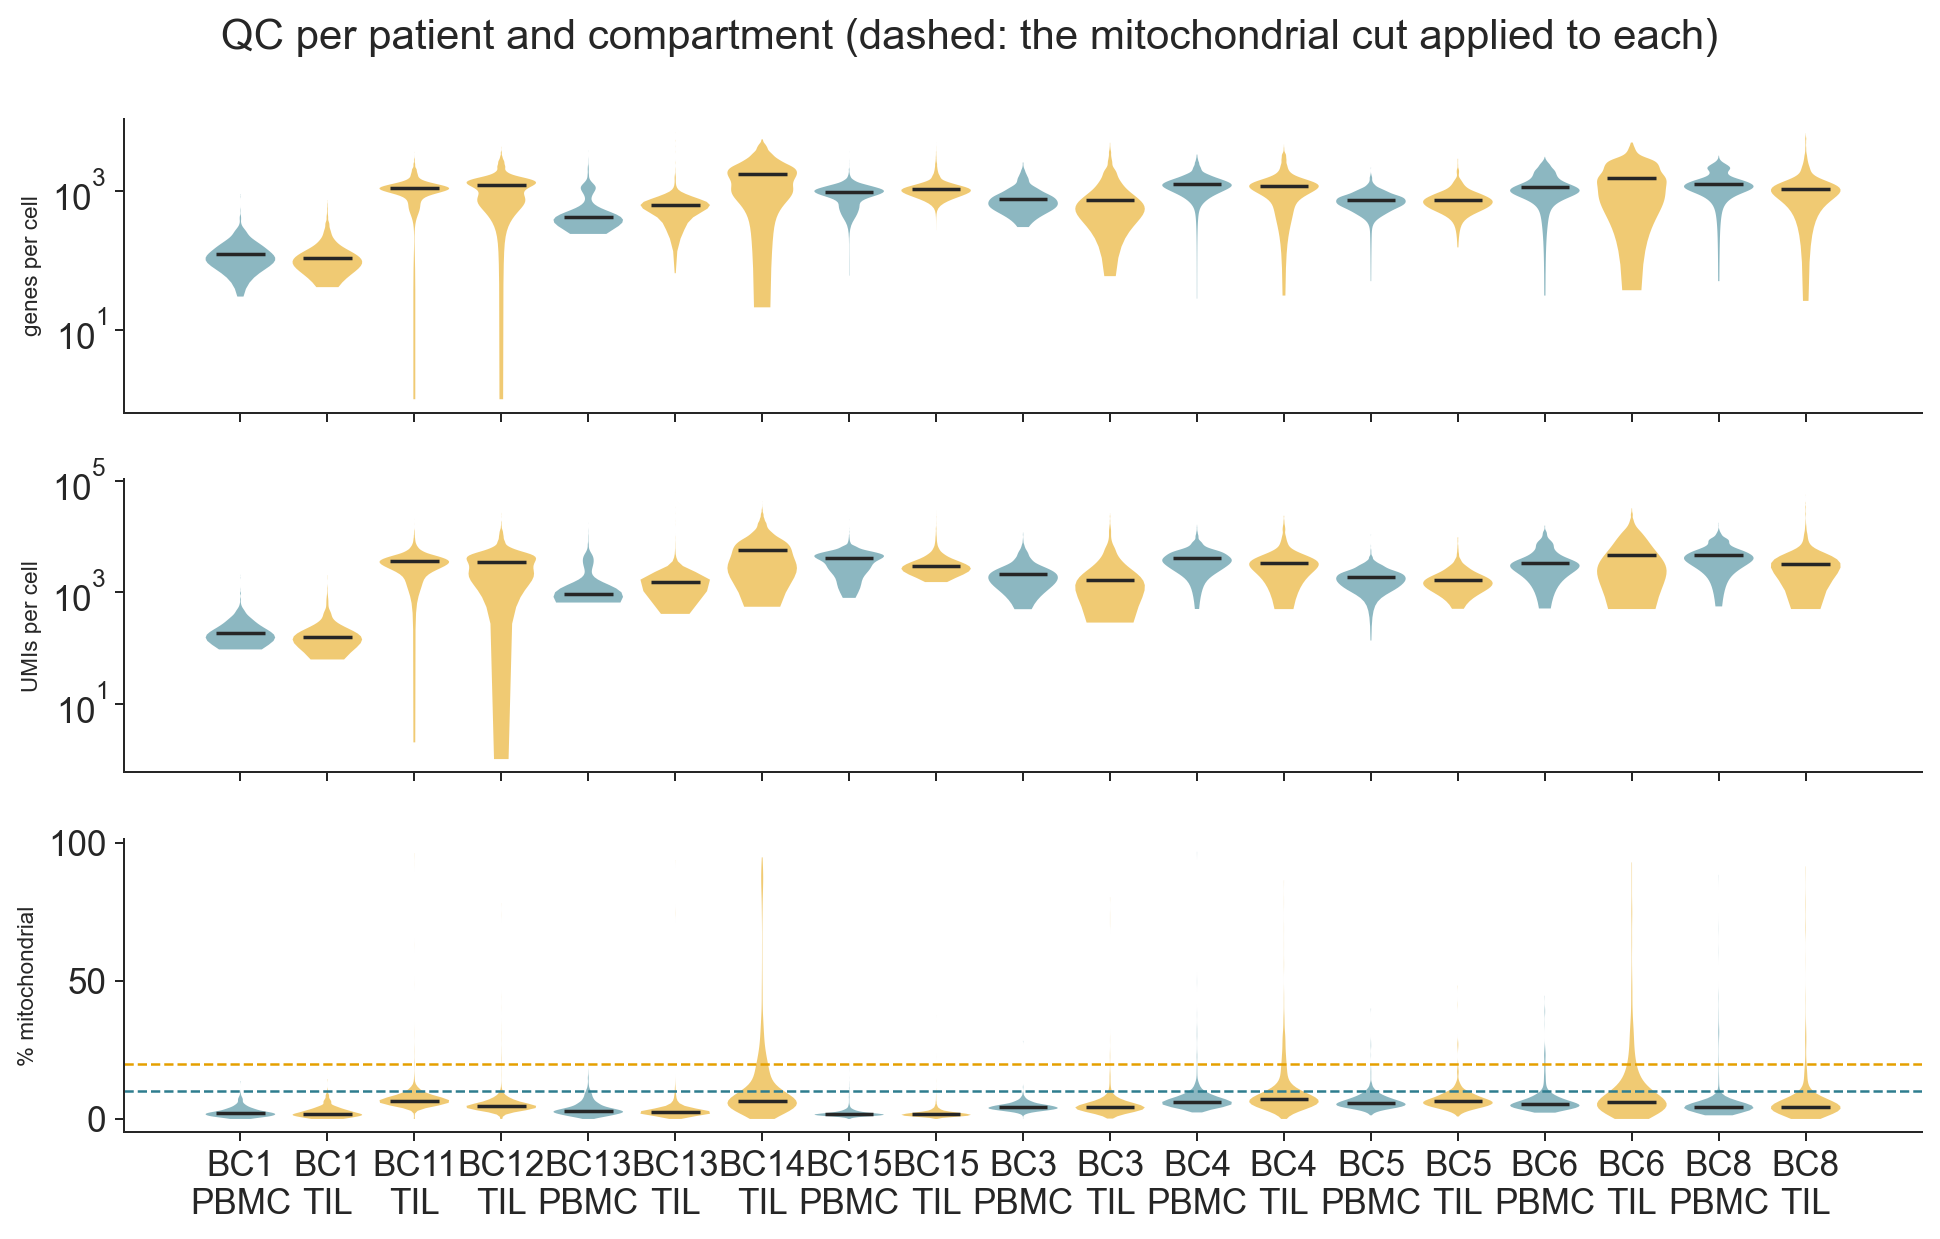

In [15]:
# inner join on Ensembl IDs; `symbol` is restored as the index afterwards
n_by_sample = {k: v.n_vars for k, v in assign.items()}
adata = ad.concat(assign, label="src", index_unique="-", merge="first")
print(f"features per sample: {sorted(set(n_by_sample.values()))} -> {adata.n_vars} shared")

adata = adata[adata.obs["compartment"].isin(["PBMC", "TIL"])].copy()
adata.var_names = pd.Index(adata.var["symbol"].astype(str))
adata.var_names_make_unique()
adata.layers["counts"] = adata.X.copy()

adata.var["mito"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.startswith(("RPS", "RPL"))
sc.pp.calculate_qc_metrics(adata, qc_vars=["mito", "ribo"], inplace=True, log1p=False, percent_top=None)

obs = adata.obs.copy()
obs["grp"] = obs["patient"].astype(str) + "\n" + obs["compartment"].astype(str)
order = sorted(obs["grp"].unique(), key=lambda g: (g.split("\n")[0], g.split("\n")[1]))
cols = ["#2e7d8f" if g.endswith("PBMC") else "#e5a000" for g in order]

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
for ax, col, lab in zip(axes, ["n_genes_by_counts", "total_counts", "pct_counts_mito"],
                        ["genes per cell", "UMIs per cell", "% mitochondrial"]):
    violin_by_group(ax, obs, "grp", col, order=order, colours=cols,
                    log=(col != "pct_counts_mito"))
    ax.set_ylabel(lab, fontsize=9)
    sns.despine(ax=ax)
axes[-1].axhline(10, color="#2e7d8f", ls="--", lw=1)
axes[-1].axhline(20, color="#e5a000", ls="--", lw=1)
axes[-1].set_xlabel("")
fig.suptitle("QC per patient and compartment (dashed: the mitochondrial cut applied to each)", y=.99)
fig.tight_layout(); fig.savefig(FIGS / "04_qc.png", bbox_inches="tight"); plt.show()

In [16]:
MITO_CUT = {"PBMC": 10, "TIL": 20}
before = adata.n_obs

keep = (
    (adata.obs["n_genes_by_counts"] >= 200) &
    (adata.obs["n_genes_by_counts"] <= 6000) &
    (adata.obs["total_counts"] >= 500) &
    (adata.obs["pct_counts_mito"] < adata.obs["compartment"].map(MITO_CUT))
)
adata = adata[keep].copy()
sc.pp.filter_genes(adata, min_cells=3)

print(f"cells {before} -> {adata.n_obs}  ({100*adata.n_obs/before:.1f}% kept), genes {adata.n_vars}")
adata.obs.groupby(["subtype", "compartment"], observed=True).size().rename("cells").to_frame()

cells 27758 -> 25521  (91.9% kept), genes 20414


cells
subtype compartment       
IDC     PBMC          3399
        TIL           5531
ILC     PBMC          4481
        TIL          12110

## 5. Normalisation and integration

> ### Decision 4 — correct patient, keep compartment
>
> - Eleven patients means eleven batches. Without correction the clusters just recover the patients.
> - `compartment` and `subtype` are what is being measured, and they are nested in the design. Correcting on anything but `patient` removes the signal.
> - The check afterwards is not only whether patients mix, but whether they mix while blood and tumour stay separate. Passing the first and failing the second means over-correction.

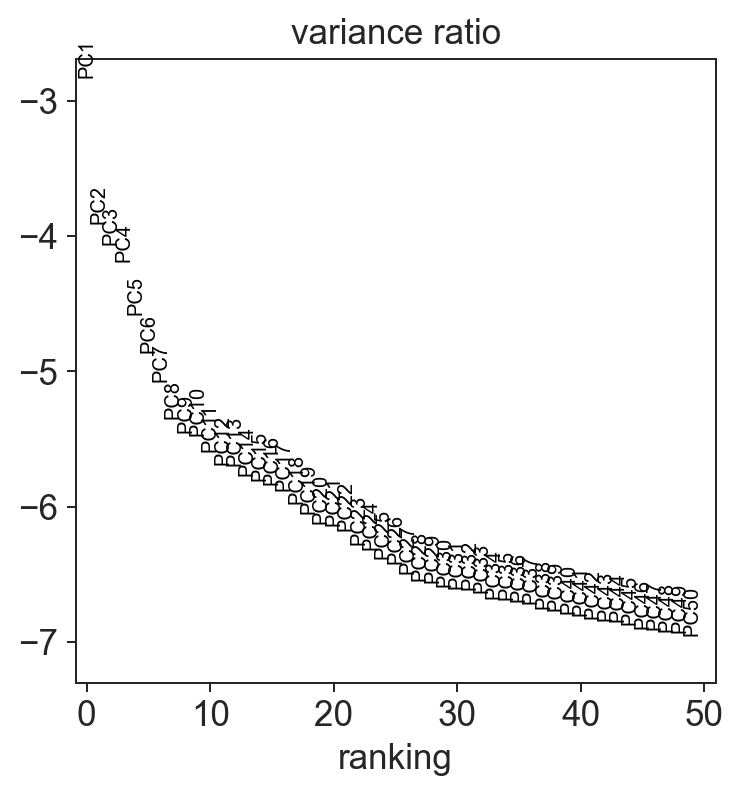

In [17]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata

sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key="patient")
adata = adata[:, adata.var["highly_variable"]].copy()

sc.pp.scale(adata, max_value=10)
sc.tl.pca(adata, n_comps=50, svd_solver="arpack", random_state=SEED)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True, show=True)

In [18]:
N_PCS = 30
try:
    sc.external.pp.harmony_integrate(adata, key="patient", basis="X_pca",
                                     adjusted_basis="X_pca_harmony", max_iter_harmony=20)
    REP = "X_pca_harmony"
    print("integrated with harmony")
except Exception as e:                      # harmonypy unavailable -> fall back
    print("harmony unavailable, falling back to ComBat:", e)
    REP = "X_pca"

sc.pp.neighbors(adata, n_neighbors=15, n_pcs=N_PCS, use_rep=REP, random_state=SEED)
sc.tl.umap(adata, random_state=SEED)
sc.tl.leiden(adata, resolution=1.0, key_added="leiden", random_state=SEED, flavor="igraph", n_iterations=2)
print(adata.obs["leiden"].value_counts().rename("cells").to_frame().T)

2026-10-15 11:34:06,003 - harmonypy - INFO - Running Harmony (PyTorch on cpu)


2026-10-15 11:34:06,003 - harmonypy - INFO -   Parameters:


2026-10-15 11:34:06,017 - harmonypy - INFO -     max_iter_harmony: 20


2026-10-15 11:34:06,017 - harmonypy - INFO -     max_iter_kmeans: 20


2026-10-15 11:34:06,019 - harmonypy - INFO -     epsilon_cluster: 1e-05


...

2026-10-15 11:34:13,531 - harmonypy - INFO - Iteration 5 of 20


2026-10-15 11:34:14,613 - harmonypy - INFO - Converged after 5 iterations


harmony unavailable, falling back to ComBat: Value passed for key 'X_pca_harmony' is of incorrect shape. Values of obsm must match dimensions ('obs',) of parent. Value had shape (50,) while it should have had (25521,).


<env>/site-packages/tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


leiden    10     1    11     4    13     8    25    15    26    17  ...   18  \
cells   2393  2150  2094  2090  2018  1843  1202  1178  1154  1064  ...  258   

leiden    9   29   16   20   28   27   22    3    0  
cells   200  186  179  158  148  132  131  124  100  

[1 rows x 30 columns]


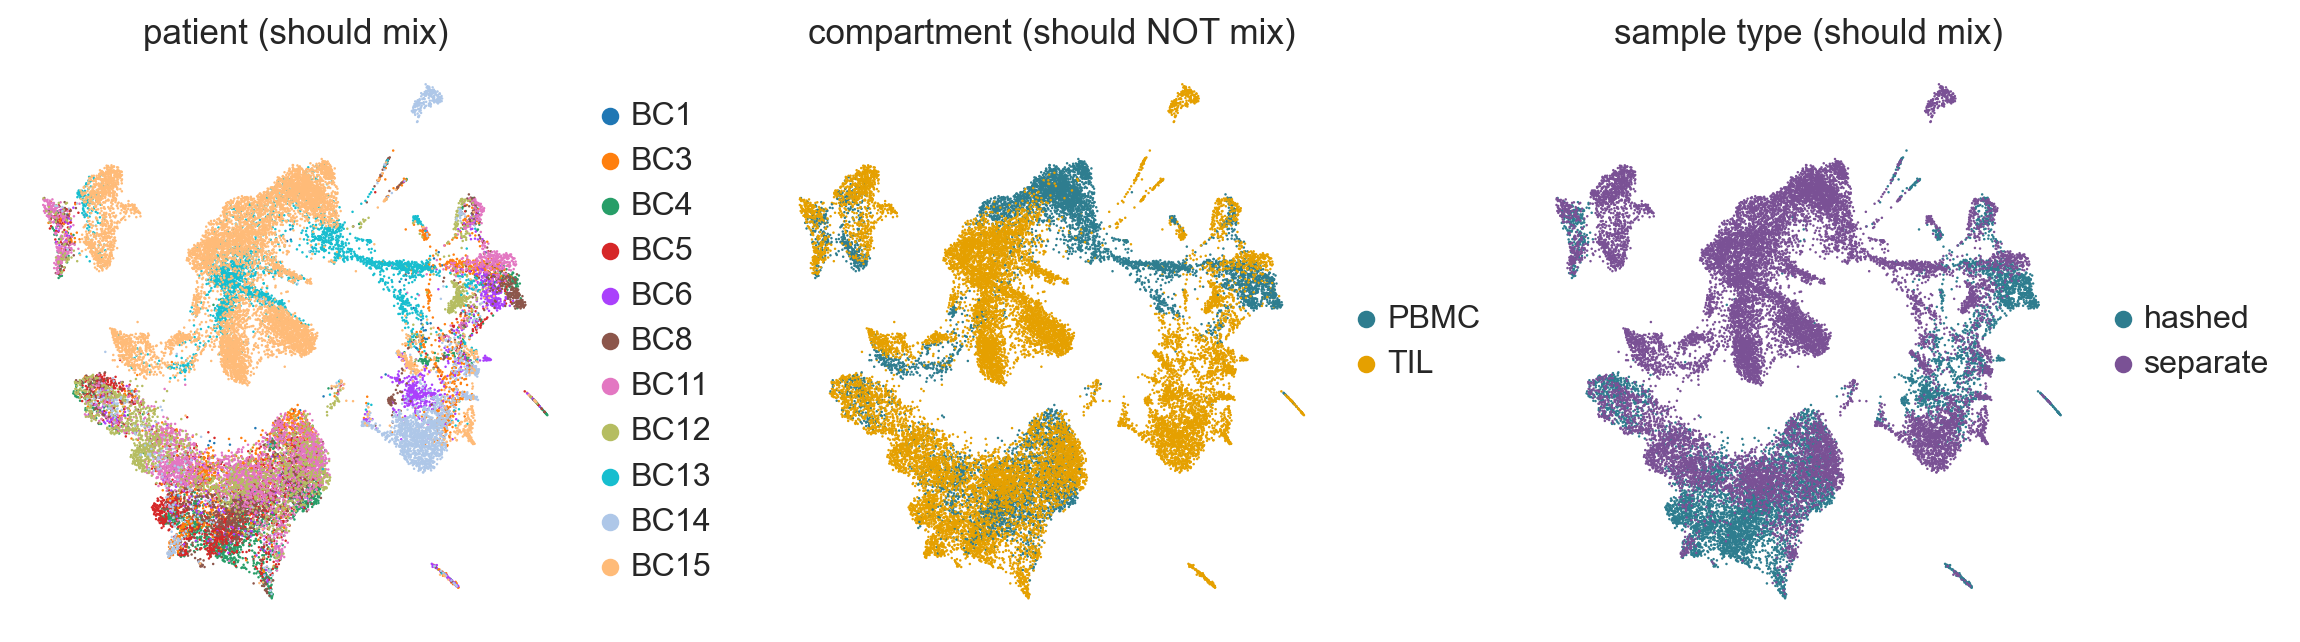

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
sc.pl.umap(adata, color="patient",     ax=axes[0], show=False, title="patient (should mix)",       s=4, frameon=False)
sc.pl.umap(adata, color="compartment", ax=axes[1], show=False, title="compartment (should NOT mix)", s=4,
           palette=["#2e7d8f", "#e5a000"], frameon=False)
sc.pl.umap(adata, color="sample_type", ax=axes[2], show=False, title="sample type (should mix)", s=4,
           palette=["#2e7d8f", "#7a5195"], frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "05_umap_integration.png", bbox_inches="tight"); plt.show()

**Reading the result**

- The upper group mixes patients well. These are the lymphocytes.
- The lower group stays patient-structured, with individual patients forming their own lobes. That is the myeloid compartment, and the structure is real — tumour macrophage programmes are patient-specific. Harmony is not pushed hard enough to flatten it.
- Blood and tumour stay separated in both groups, which is the check that matters.
- This is why §7 and §9 treat the patient as the unit rather than pooling cells.

## 6. Annotation

Marker-based on the clusters above, using the standard CD45+ panel. Labels come from the dot plot rather than a reference, so they can be checked.

categories: 0, 1, 2, etc.
var_group_labels: T / NK, B / plasma, Myeloid, etc.


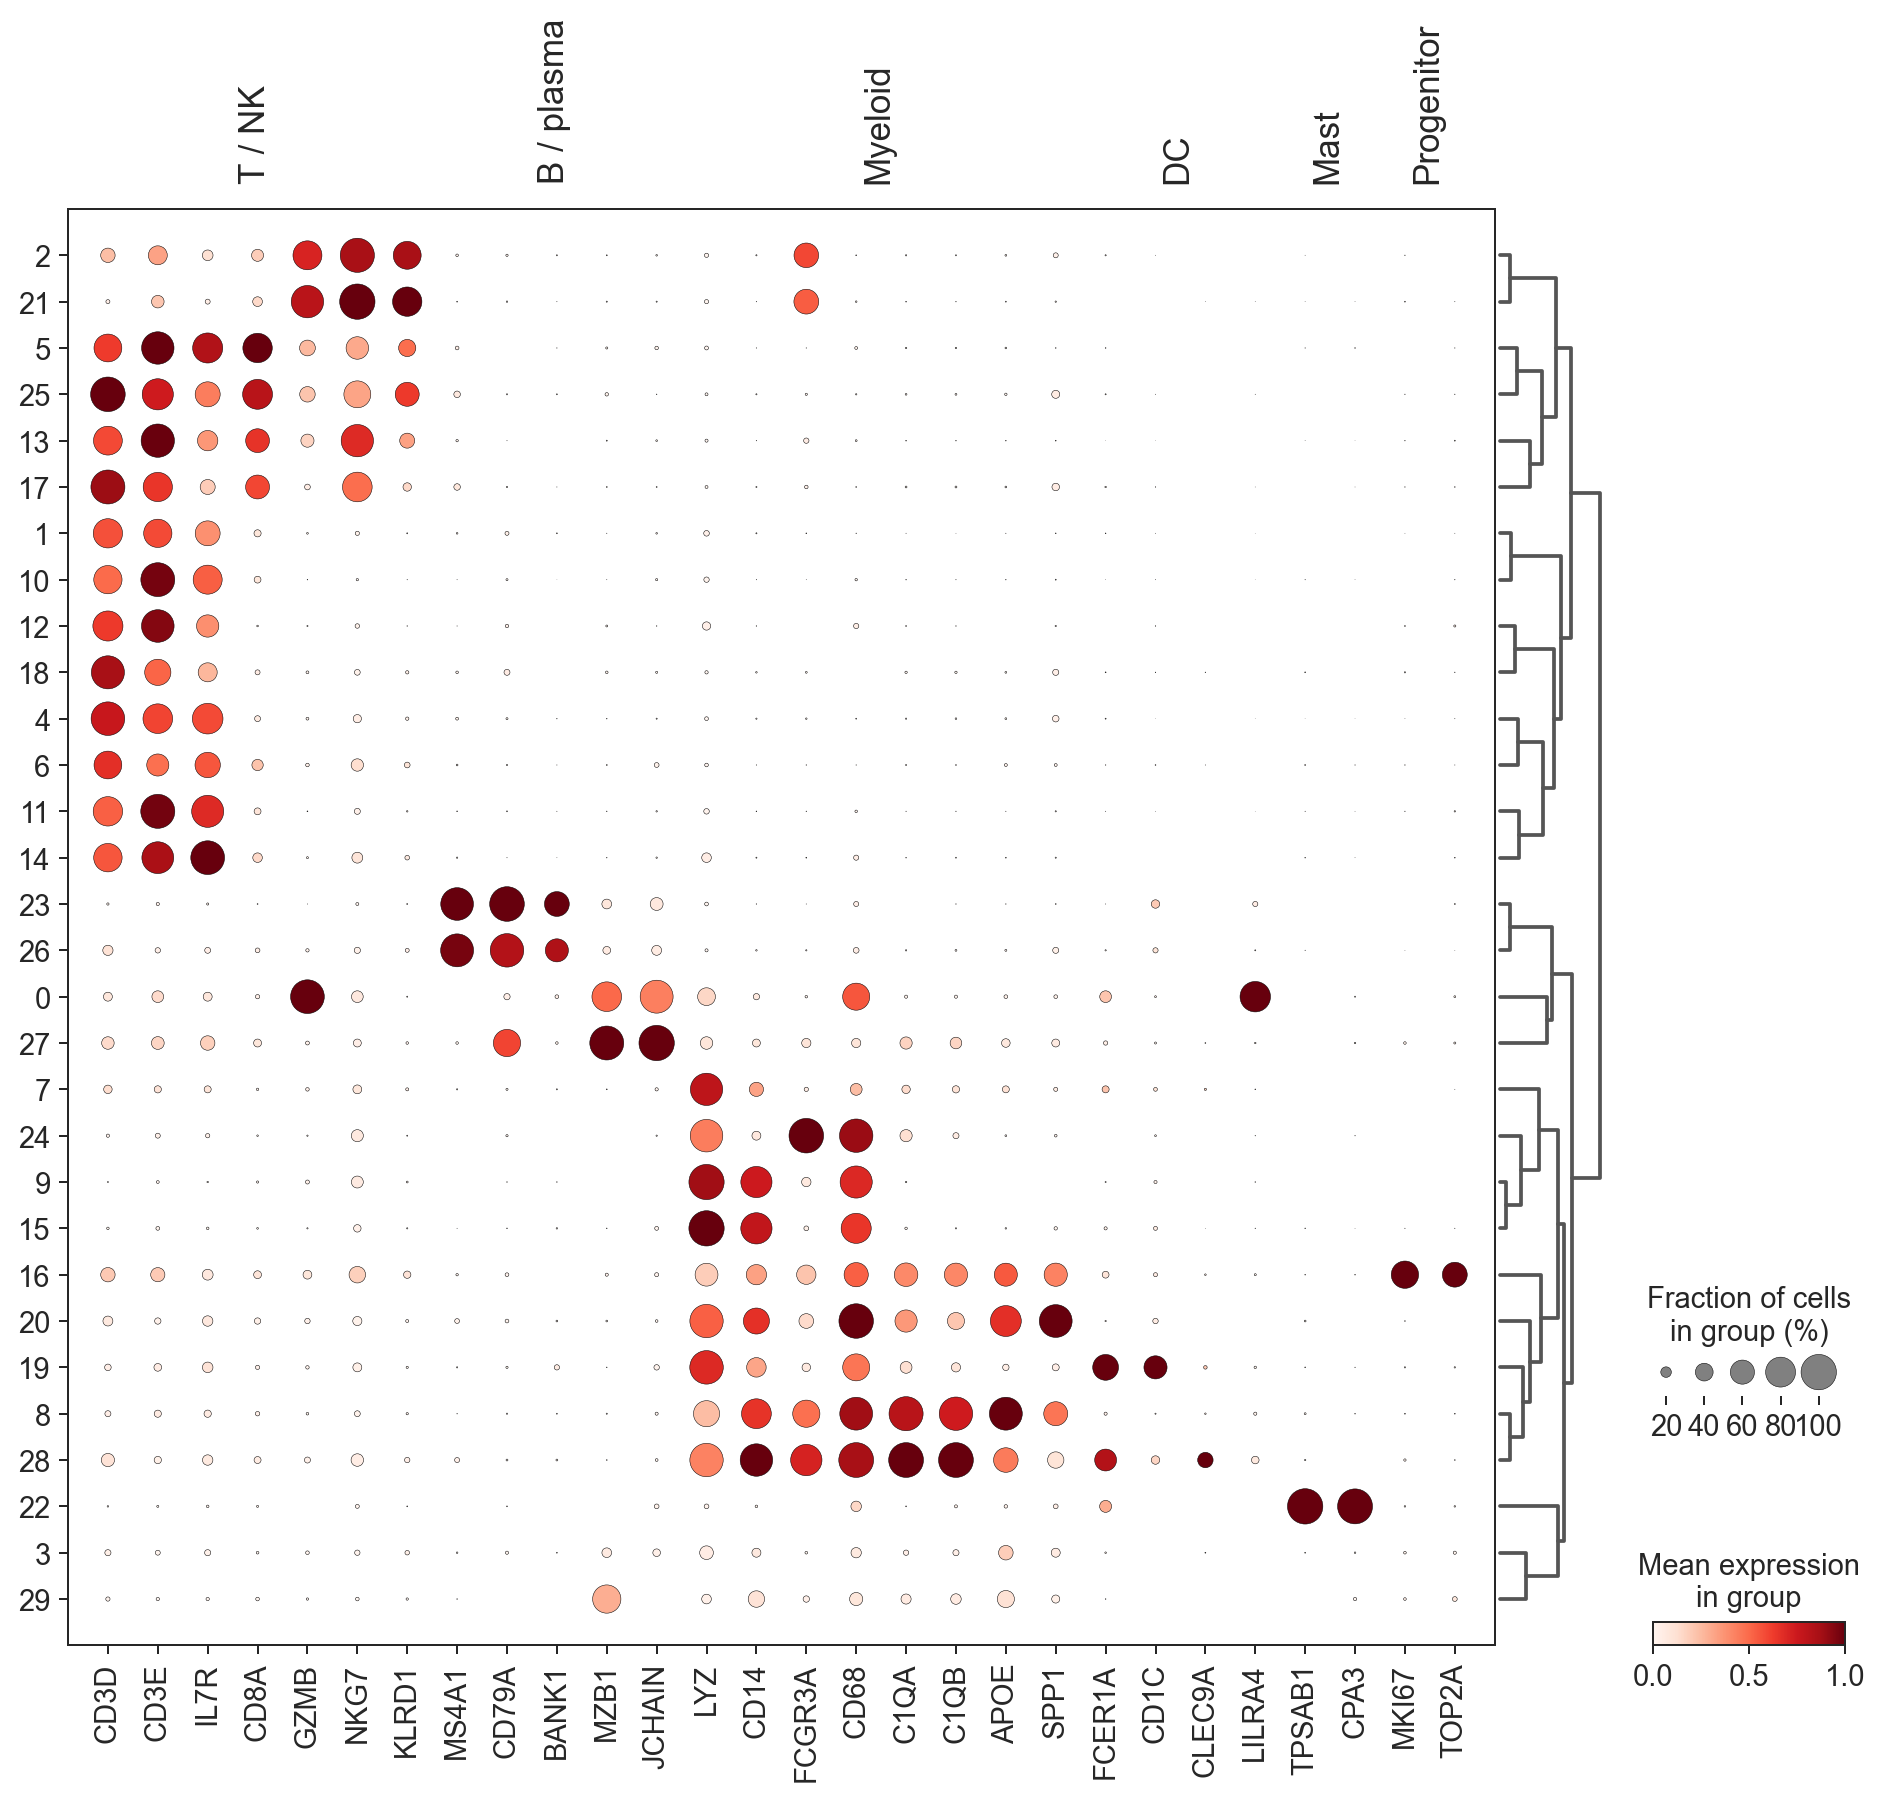

In [20]:
MARKERS = {
    "T / NK":     ["CD3D", "CD3E", "IL7R", "CD8A", "GZMB", "NKG7", "KLRD1"],  # TRAC absent from one build
    "B / plasma": ["MS4A1", "CD79A", "BANK1", "MZB1", "JCHAIN"],
    "Myeloid":    ["LYZ", "CD14", "FCGR3A", "CD68", "C1QA", "C1QB", "APOE", "SPP1"],
    "DC":         ["FCER1A", "CD1C", "CLEC9A", "LILRA4"],
    "Mast":       ["TPSAB1", "CPA3"],
    "Progenitor": ["MKI67", "TOP2A"],
}
sc.tl.dendrogram(adata, groupby="leiden")
sc.pl.dotplot(adata, MARKERS, groupby="leiden", standard_scale="var",
              dendrogram=True, show=True, save="_markers.png")

celltype  T / NK  Myeloid  Other  B / plasma  Progenitor  Mast
cells      15715     5116   2460        1920         179   131


<env>/site-packages/scanpy\tools\_rank_genes_groups.py:458: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
<env>/site-packages/scanpy\tools\_rank_genes_groups.py:460: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
<env>/site-packages/scanpy\tools\_rank_genes_groups.py:463: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor perfor

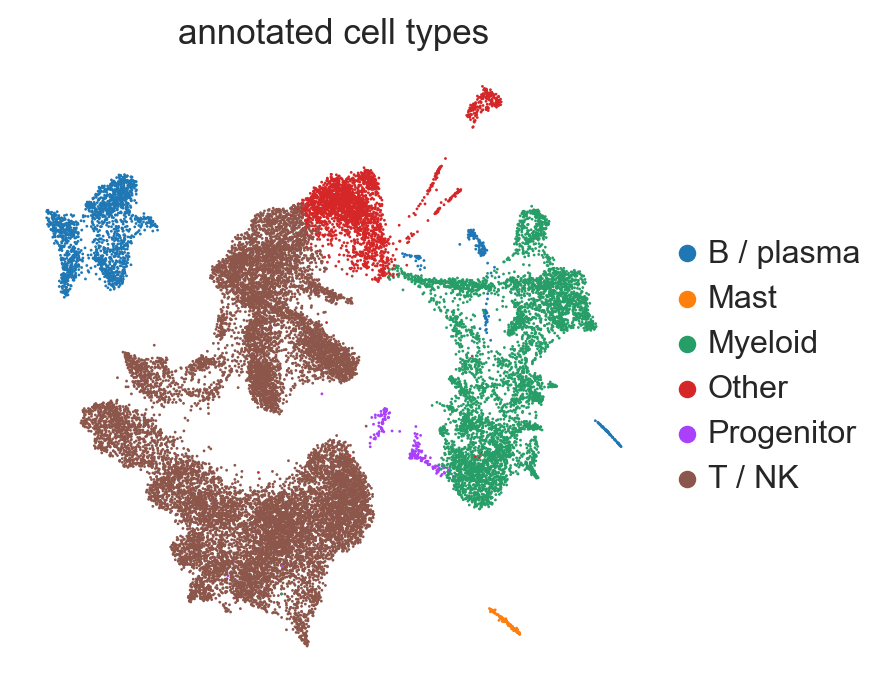

In [21]:
# edit after reading the dot plot above
ANNOT = {
    "T / NK":     [],
    "B / plasma": [],
    "Myeloid":    [],
    "DC":         [],
    "Mast":       [],
    "Proliferating": [],
}

def auto_annotate(adata, markers):
    # Fallback: score each cluster on each marker set and take the argmax.
    sc.tl.rank_genes_groups(adata, "leiden", method="wilcoxon", n_genes=50)
    top = pd.DataFrame(adata.uns["rank_genes_groups"]["names"])
    lab = {}
    for cl in top.columns:
        genes = set(top[cl])
        hits = {k: len(genes & set(v)) for k, v in markers.items()}
        lab[cl] = max(hits, key=hits.get) if max(hits.values()) > 0 else "Other"
    return lab

if not any(ANNOT.values()):
    mapping = auto_annotate(adata, MARKERS)
else:
    mapping = {cl: lab for lab, cls in ANNOT.items() for cl in cls}

adata.obs["celltype"] = adata.obs["leiden"].map(mapping).astype("category")
print(adata.obs["celltype"].value_counts().rename("cells").to_frame().T)

sc.pl.umap(adata, color="celltype", legend_loc="right margin", s=5, frameon=False,
           title="annotated cell types", save="_celltype.png")

## 7. Composition

> ### Decision 5 — patient as the unit, not cell
>
> - A χ² on the cell-by-group table would return very small p-values with 25,000 cells.
> - It treats each cell as independent. Cells within a patient are correlated, and n is 5–6 patients per arm.
> - Proportions are computed per patient and tested across patients.
> - This only detects large, consistent effects. That is the correct sensitivity for this design.

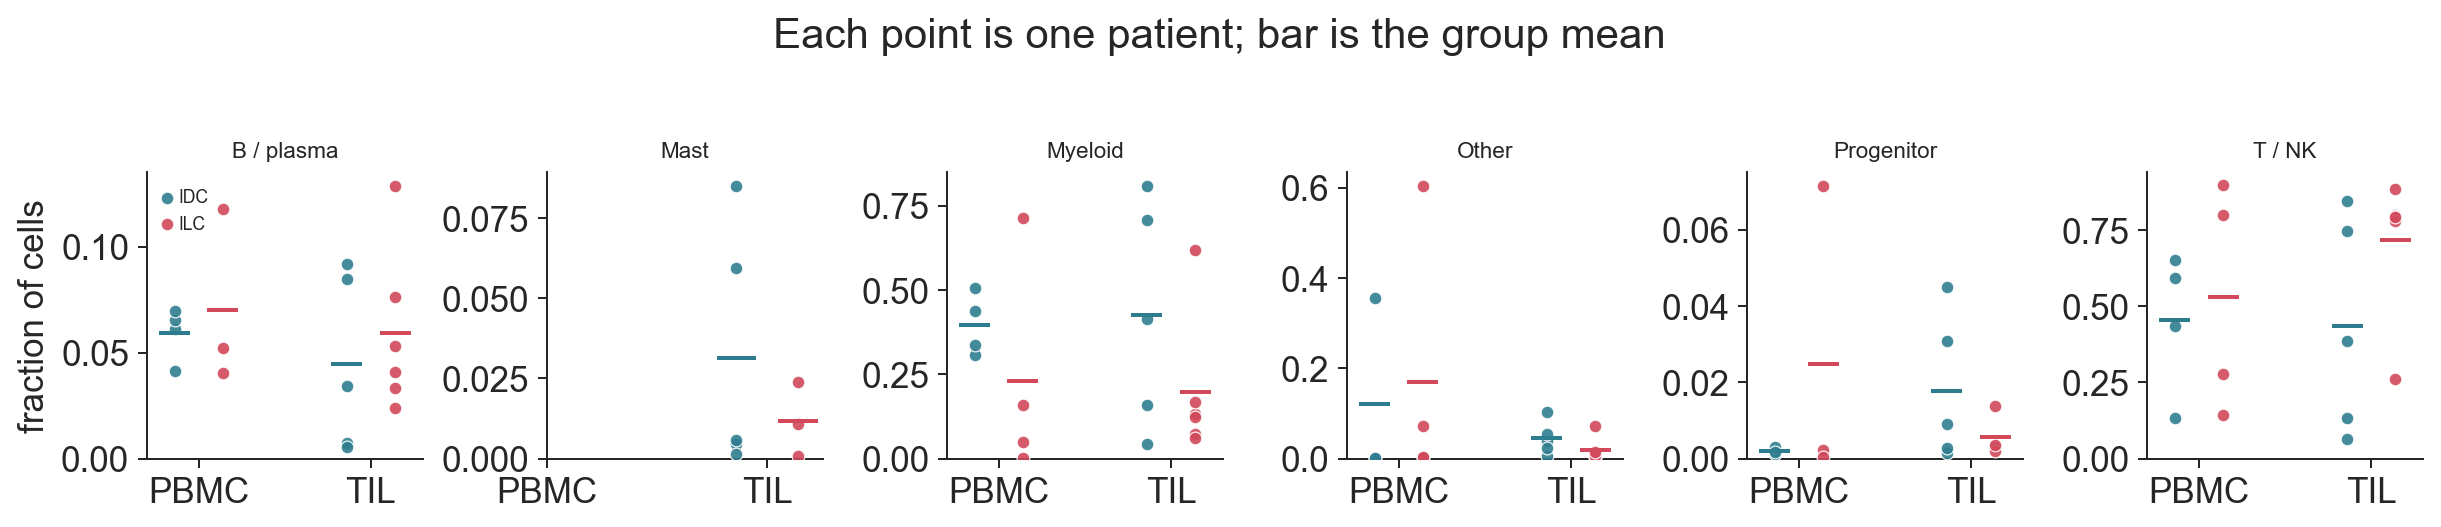

In [22]:
comp = (adata.obs.groupby(["patient", "subtype", "compartment", "celltype"], observed=True)
        .size().rename("n").reset_index())
comp["frac"] = comp["n"] / comp.groupby(["patient", "compartment"], observed=True)["n"].transform("sum")

cts = [c for c in comp["celltype"].cat.categories if c in set(comp["celltype"])] \
      if hasattr(comp["celltype"], "cat") else sorted(comp["celltype"].unique())
ncol = min(len(cts), 6)
nrow = int(np.ceil(len(cts) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(2.3 * ncol, 2.9 * nrow), squeeze=False, sharey=False)

for ax, ct in zip(axes.ravel(), cts):
    d = comp[comp["celltype"] == ct]
    for j, (sub, colour) in enumerate([("IDC", "#2e7d8f"), ("ILC", "#d1495b")]):
        for i, cp in enumerate(["PBMC", "TIL"]):
            v = d.loc[(d["subtype"] == sub) & (d["compartment"] == cp), "frac"].values
            x = i + (j - .5) * .28
            ax.scatter(np.full(len(v), x), v, s=26, color=colour, alpha=.9,
                       edgecolor="white", linewidth=.5, zorder=3,
                       label=sub if (i == 0 and ax is axes.ravel()[0]) else None)
            if len(v): ax.hlines(v.mean(), x - .09, x + .09, color=colour, lw=1.6, zorder=4)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["PBMC", "TIL"])
    ax.set_title(ct, fontsize=9); ax.set_ylim(bottom=0)
    sns.despine(ax=ax)
for ax in axes.ravel()[len(cts):]: ax.axis("off")
axes.ravel()[0].set_ylabel("fraction of cells")
axes.ravel()[0].legend(fontsize=7, frameon=False)
fig.suptitle("Each point is one patient; bar is the group mean", y=1.02)
fig.tight_layout(); fig.savefig(FIGS / "06_composition.png", bbox_inches="tight"); plt.show()

In [23]:
rows = []
for (ct, cp), d in comp.groupby(["celltype", "compartment"], observed=True):
    a = d.loc[d["subtype"] == "IDC", "frac"].values
    b = d.loc[d["subtype"] == "ILC", "frac"].values
    if len(a) < 2 or len(b) < 2: continue
    u, pv = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"celltype": ct, "compartment": cp,
                 "IDC mean": round(a.mean(), 3), "ILC mean": round(b.mean(), 3),
                 "diff": round(a.mean() - b.mean(), 3), "p (Mann-Whitney)": round(pv, 3)})
res = pd.DataFrame(rows).sort_values("p (Mann-Whitney)")
n_til = comp.loc[comp["compartment"] == "TIL"].groupby("subtype", observed=True)["patient"].nunique()
print("tumour arm: " + ", ".join(f"{k} n={v}" for k, v in n_til.items()))
res

tumour arm: IDC n=5, ILC n=6


,celltype,compartment,IDC mean,ILC mean,diff,p (Mann-Whitney)
10,T / NK,TIL,0.435,0.718,-0.283,0.177
6,Other,TIL,0.045,0.020,0.025,0.310
4,Myeloid,TIL,0.427,0.196,0.230,0.329
3,Myeloid,PBMC,0.397,0.231,0.166,0.343
5,Other,PBMC,0.120,0.170,-0.050,0.629
1,B / plasma,TIL,0.045,0.059,-0.015,0.662
9,T / NK,PBMC,0.453,0.529,-0.076,0.686
8,Progenitor,TIL,0.018,0.006,0.012,0.730
2,Mast,TIL,0.031,0.012,0.019,0.786
0,B / plasma,PBMC,0.059,0.070,-0.011,0.857


## 8. Myeloid cells

The reported difference in this cohort is in macrophages. Sub-clustering the myeloid cells separately keeps the much larger T-cell compartment from dominating variable-gene selection.

5116 myeloid/DC cells, 20414 genes


2026-10-15 11:35:41,838 - harmonypy - INFO - Running Harmony (PyTorch on cpu)


2026-10-15 11:35:41,838 - harmonypy - INFO -   Parameters:


2026-10-15 11:35:41,838 - harmonypy - INFO -     max_iter_harmony: 10


2026-10-15 11:35:41,838 - harmonypy - INFO -     max_iter_kmeans: 20


...

2026-10-15 11:35:44,704 - harmonypy - INFO - Iteration 7 of 10


2026-10-15 11:35:45,001 - harmonypy - INFO - Iteration 8 of 10


2026-10-15 11:35:45,315 - harmonypy - INFO - Iteration 9 of 10


2026-10-15 11:35:45,629 - harmonypy - INFO - Iteration 10 of 10


2026-10-15 11:35:45,922 - harmonypy - INFO - Stopped before convergence


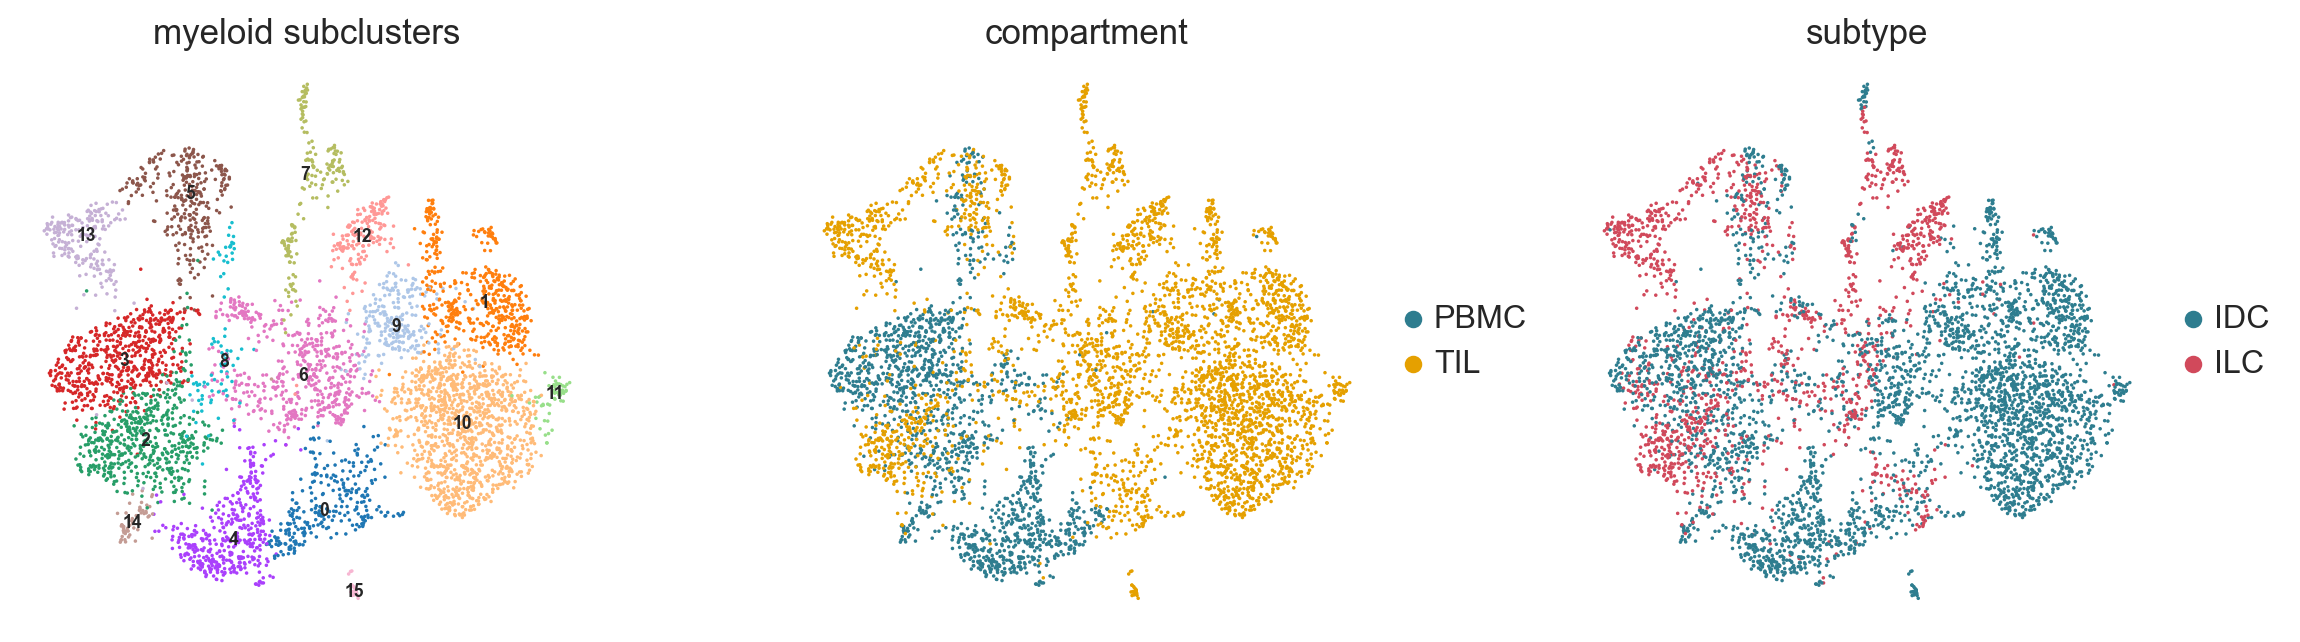

In [24]:
# all-gene, log-normalised copy of the myeloid cells -- used for plotting markers
is_mye = adata.obs["celltype"].isin(["Myeloid", "DC"]).values
mye_full = adata.raw.to_adata()[adata.obs_names[is_mye]].copy()
mye_full.obs = adata.obs.loc[mye_full.obs_names].copy()
print(f"{mye_full.n_obs} myeloid/DC cells, {mye_full.n_vars} genes")

# separate HVG copy for the embedding, so scaling does not touch mye_full
mye = mye_full.copy()
sc.pp.highly_variable_genes(mye, n_top_genes=1500, batch_key="patient")
mye = mye[:, mye.var["highly_variable"]].copy()
sc.pp.scale(mye, max_value=10)
sc.tl.pca(mye, n_comps=30, svd_solver="arpack", random_state=SEED)
try:
    sc.external.pp.harmony_integrate(mye, key="patient", basis="X_pca", adjusted_basis="X_pca_harmony")
    rep = "X_pca_harmony"
except Exception:
    rep = "X_pca"
sc.pp.neighbors(mye, n_neighbors=15, n_pcs=20, use_rep=rep, random_state=SEED)
sc.tl.umap(mye, random_state=SEED)
sc.tl.leiden(mye, resolution=0.6, key_added="mye_cluster", random_state=SEED,
             flavor="igraph", n_iterations=2)

# carry the labels and embedding back onto the all-gene object
mye_full.obs["mye_cluster"] = mye.obs["mye_cluster"].values
mye_full.obsm["X_umap"] = mye.obsm["X_umap"]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
sc.pl.umap(mye, color="mye_cluster", ax=axes[0], show=False, s=8, legend_loc="on data",
           legend_fontsize=7, title="myeloid subclusters", frameon=False)
sc.pl.umap(mye, color="compartment", ax=axes[1], show=False, s=8, palette=["#2e7d8f", "#e5a000"],
           title="compartment", frameon=False)
sc.pl.umap(mye, color="subtype", ax=axes[2], show=False, s=8, palette=["#2e7d8f", "#d1495b"],
           title="subtype", frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "07_myeloid_umap.png", bbox_inches="tight"); plt.show()

In [25]:
MYE_MARKERS = {
    "Monocyte":    ["CD14", "FCGR3A", "S100A8", "S100A9", "VCAN", "FCN1"],
    "Macrophage":  ["C1QA", "C1QB", "APOE", "TREM2", "SPP1", "MRC1", "CD68"],
    "IFN-licensed": ["CXCL9", "CXCL10", "IDO1", "GBP1"],
    "DC":          ["FCER1A", "CD1C", "CLEC9A", "LILRA4"],
}
present = {k: [g for g in v if g in mye_full.var_names] for k, v in MYE_MARKERS.items()}
present = {k: v for k, v in present.items() if v}

sc.pl.dotplot(mye_full, present, groupby="mye_cluster", standard_scale="var",
              show=False, save="_myeloid.png")
plt.show()

## 9. Pseudobulk differential expression

> ### Decision 6 — aggregate, then test
>
> - Cell-level Wilcoxon has the same problem as the χ² above, and myeloid cells vary a lot between patients.
> - Counts are summed per patient per compartment, so each patient contributes one observation. Testing is across patients.

In [26]:
raw = mye_full            # all genes, log-normalised, myeloid only

def pseudobulk(a, keys):
    idx = a.obs[keys].astype(str).agg("|".join, axis=1)
    out, meta = [], []
    for k, cells in idx.groupby(idx).groups.items():
        x = a[list(cells)].X
        out.append(np.asarray(x.sum(0)).ravel())
        meta.append(dict(zip(keys, k.split("|")), n_cells=len(cells)))
    return pd.DataFrame(out, columns=a.var_names), pd.DataFrame(meta)

pb, pbmeta = pseudobulk(raw, ["patient", "subtype", "compartment", "sample_type"])
pbmeta["n_cells"] = pbmeta["n_cells"].astype(int)
pb = pb.loc[pbmeta["n_cells"] >= 25].reset_index(drop=True)
pbmeta = pbmeta.loc[pbmeta["n_cells"] >= 25].reset_index(drop=True)
print(pbmeta.to_string(index=False))

patient subtype compartment sample_type  n_cells
   BC11     ILC         TIL    separate      369
   BC12     ILC         TIL    separate      308
   BC13     IDC        PBMC    separate      535
   BC13     IDC         TIL    separate       67
   BC14     IDC         TIL    separate     1352
   BC15     ILC         TIL    separate      333
    BC1     ILC         TIL      hashed       26
    BC3     IDC        PBMC      hashed      280
    BC3     IDC         TIL      hashed      369
    BC4     ILC        PBMC      hashed      144
    BC4     ILC         TIL      hashed      121
    BC5     ILC        PBMC      hashed       42
    BC5     ILC         TIL      hashed       70
    BC6     IDC        PBMC      hashed      290
    BC6     IDC         TIL      hashed      447
    BC8     IDC        PBMC      hashed      232
    BC8     IDC         TIL      hashed      106


In [27]:
cpm = np.log1p(pb.div(pb.sum(1), axis=0) * 1e6)
expressed = cpm.columns[(cpm > 1).sum(0) >= 4]
cpm = cpm[expressed]

def paired_de(meta, mat, group_col, a_lab, b_lab, within=None):
    rows = []
    sel = meta.copy()
    if within: sel = sel[sel["compartment"] == within]
    ia = sel.index[sel[group_col] == a_lab]; ib = sel.index[sel[group_col] == b_lab]
    for g in mat.columns:
        x, y = mat.loc[ia, g].values, mat.loc[ib, g].values
        if len(x) < 2 or len(y) < 2: continue
        _, pv = stats.mannwhitneyu(x, y, alternative="two-sided")
        rows.append({"gene": g, "lfc": x.mean() - y.mean(), "p": pv})
    return pd.DataFrame(rows).sort_values("p")

de_comp = paired_de(pbmeta, cpm, "compartment", "TIL", "PBMC")
print("TIL vs PBMC, myeloid — top genes")
de_comp.head(15).to_string(index=False)

TIL vs PBMC, myeloid — top genes


'      gene       lfc        p\n    ZNF467 -1.484950 0.000162\n      USO1  0.654682 0.000162\n     BASP1  0.868327 0.000162\n     PSMC2  0.932782 0.000162\n    S100A9 -1.552276 0.000162\n   S100A12 -2.251707 0.000162\n       GSN  1.323913 0.000162\n    S100A8 -1.734661 0.000162\n      SCOC  1.534765 0.000162\n       AEN  1.907512 0.000162\n      TSPO -0.508816 0.000162\n     CDC42 -0.340643 0.000162\nAC098613.1  1.602218 0.000162\n    PAPOLA -0.331152 0.000162\n      STX7  0.541488 0.000323'

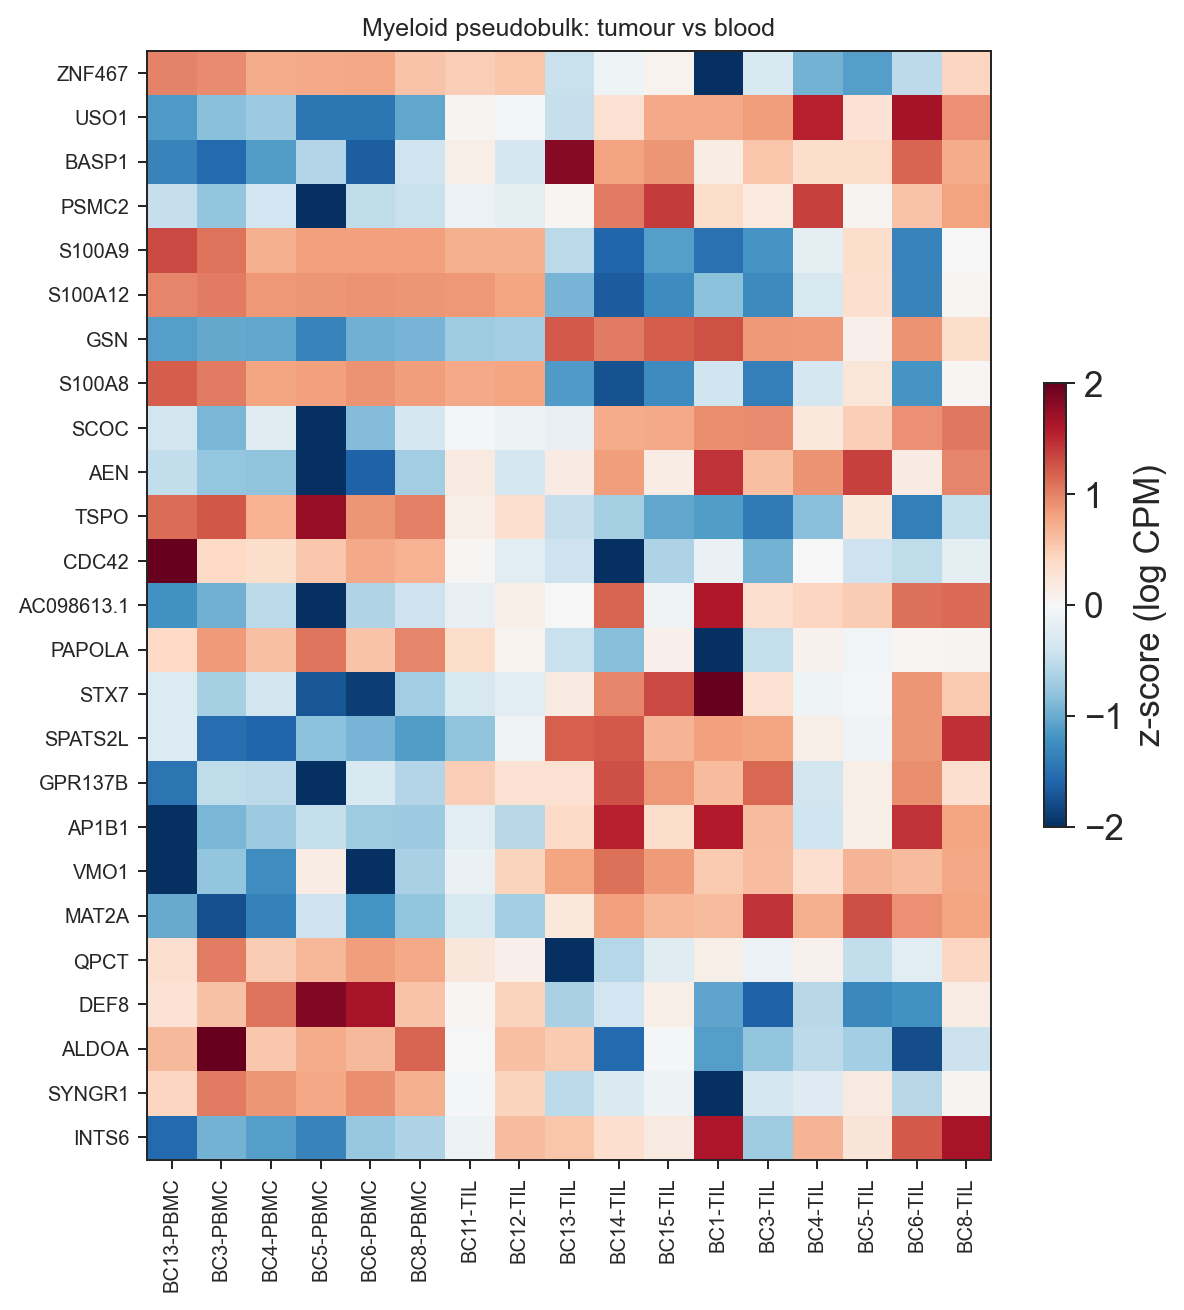

In [28]:
top = de_comp.head(25)["gene"].tolist()
hm = cpm[top].T
hm.columns = [f"{r.patient}-{r.compartment}" for r in pbmeta.itertuples()]
hm = hm[sorted(hm.columns, key=lambda c: c.split("-")[1])]
z = hm.sub(hm.mean(1), axis=0).div(hm.std(1) + 1e-9, axis=0)

fig, ax = plt.subplots(figsize=(7, 7.5))
im = ax.imshow(z.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax.set_xticks(range(z.shape[1])); ax.set_xticklabels(z.columns, rotation=90, fontsize=8)
ax.set_yticks(range(z.shape[0])); ax.set_yticklabels(z.index, fontsize=8)
ax.set_title("Myeloid pseudobulk: tumour vs blood", fontsize=10)
fig.colorbar(im, ax=ax, shrink=.4, label="z-score (log CPM)")
fig.tight_layout(); fig.savefig(FIGS / "08_pseudobulk_heatmap.png", bbox_inches="tight"); plt.show()

In [29]:
de_sub = paired_de(pbmeta, cpm, "subtype", "IDC", "ILC", within="TIL")
n_idc = pbmeta.query("compartment == 'TIL' and subtype == 'IDC'").patient.nunique()
n_ilc = pbmeta.query("compartment == 'TIL' and subtype == 'ILC'").patient.nunique()
print(f"IDC vs ILC within tumour myeloid — n = {n_idc} vs {n_ilc} patients")
de_sub.head(15).to_string(index=False)

IDC vs ILC within tumour myeloid — n = 5 vs 6 patients


'      gene       lfc        p\n   PLEKHH1  1.752066 0.003890\n     CLDN4  1.868026 0.003890\n    GNPDA1  0.650111 0.004329\n    UBE2J2 -0.248098 0.004329\n       GBA  1.371495 0.004329\n   NCKIPSD  1.159782 0.004329\nAC009948.1  1.305613 0.004329\n   ALDH7A1  2.085059 0.004329\n     SMCO4 -0.583259 0.004329\n     SCN1B  1.954481 0.004329\n      CRYZ  1.722027 0.004329\n       FYN -0.849315 0.004329\n    SUPT7L  0.965908 0.004329\n    EIF2B5 -0.382023 0.004329\n    HNRNPM -0.231896 0.004329'

## 10. Results

**Established in the notebook rather than assumed**

- The compartment label came from a separate hashtag matrix and was checked against expression (circulating vs residency markers, mitochondrial fraction) before use.
- One of eleven patients was unusable. It was found from the hashing statistics and removed before it affected anything.
- The series mixes two CellRanger references. A symbol join would have dropped a third of the genes, including markers used here.
- Integration removes patient identity from the lymphoid compartment and keeps the blood/tumour axis. The myeloid compartment stays patient-structured, which is why the patient is the unit everywhere downstream.

**Myeloid, tumour vs blood**

- The strongest signal is loss of the S100 alarmin programme: `S100A8`, `S100A9` and `S100A12` are all down in TIL myeloid relative to PBMC, log fold-change −1.5 to −2.3, *p* ≈ 1.6 × 10⁻⁴ across 11 patients.
- That is the expected direction for monocytes differentiating into tissue macrophages, and it holds across patients rather than depending on a few cells.

**Subtype**

- Intratumoural myeloid fraction is 0.43 in IDC vs 0.20 in ILC. T/NK runs the other way, 0.44 vs 0.72.
- Neither is significant: *p* = 0.33 and 0.18 at 5 vs 6 patients.
- The direction matches what the paper reports. This sample size supports the direction, not the claim. The full 27-sample cohort is what that question needs.
- `CLDN4` in the top IDC-vs-ILC myeloid genes points to residual epithelial signal in the myeloid gate, so that list needs care.

### Limitations

- Eleven patients, to keep the runtime around three minutes.
- No ambient RNA correction — the processed GEO submission has no empty-droplet matrices.
- Doublets are only handled through the hashtag call. That catches inter-compartment doublets, not intra-compartment ones, and does nothing for the five non-hashed libraries.
- `TRAC` is absent from one reference build and was removed from the marker panel.

### Reproducing

```
bash 00_download_data.sh
conda env create -f environment.yml
conda activate sc-demo
jupyter lab er_breast_immune_scrnaseq.ipynb
```